# Non-linear Models using `keras.models.Model`

In [12]:
from keras.models import Model
from keras.layers import (
    Input,
    Dense,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Rescaling,
    ReLU,
    Flatten,
    Dropout,
    concatenate
)
from keras.applications.vgg16 import VGG16, preprocess_input
from keras.utils import plot_model

# Example 1 : 1 input and 2 outputs

Input : Human Face Image

Output :
1. Age
2. Gender

In [9]:
# Input Image
input_layer = Input(shape=(256, 256, 3))

# Normalization
x = Rescaling(1./255)(input_layer)

# Convolutional Blocks
x = Conv2D(32, kernel_size=(2,2), strides=2, padding='valid')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D()(x)

x = Conv2D(64, kernel_size=(2,2), strides=2, padding='valid')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D()(x)

x = Conv2D(128, kernel_size=(2,2), strides=2, padding='valid')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D()(x)

# Flatten feature map for Dense layers
x = Flatten()(x)

# Age Output
y = Dense(128, activation='relu')(x)
age_output = Dense(1, activation='linear', name='age_output')(y)

# Gender Output
z = Dense(128, activation='relu')(x)
gender_output = Dense(1, activation='sigmoid', name='gender_output')(z)

model = Model(inputs=input_layer, outputs=[age_output, gender_output])
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 256, 256,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │        416 │ rescaling_3[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_9 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 64, 64,    │          0 │ re_lu_9[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │      8,256 │ max_pooling2d_9[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_10 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 16, 16,    │          0 │ re_lu_10[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 8, 8, 128) │     32,896 │ max_pooling2d_10… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_11 (ReLU)     │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 4, 4, 128) │          0 │ re_lu_11[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 2048)      │          0 │ max_pooling2d_11… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │    262,272 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 128)       │    262,272 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_output (Dense)  │ (None, 1)         │        129 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender_output       │ (None, 1)         │        129 │ dense_11[0][0]  

 Total params: 567,266 (2.16 MB)

 Trainable params: 566,818 (2.16 MB)

 Non-trainable params: 448 (1.75 KB)

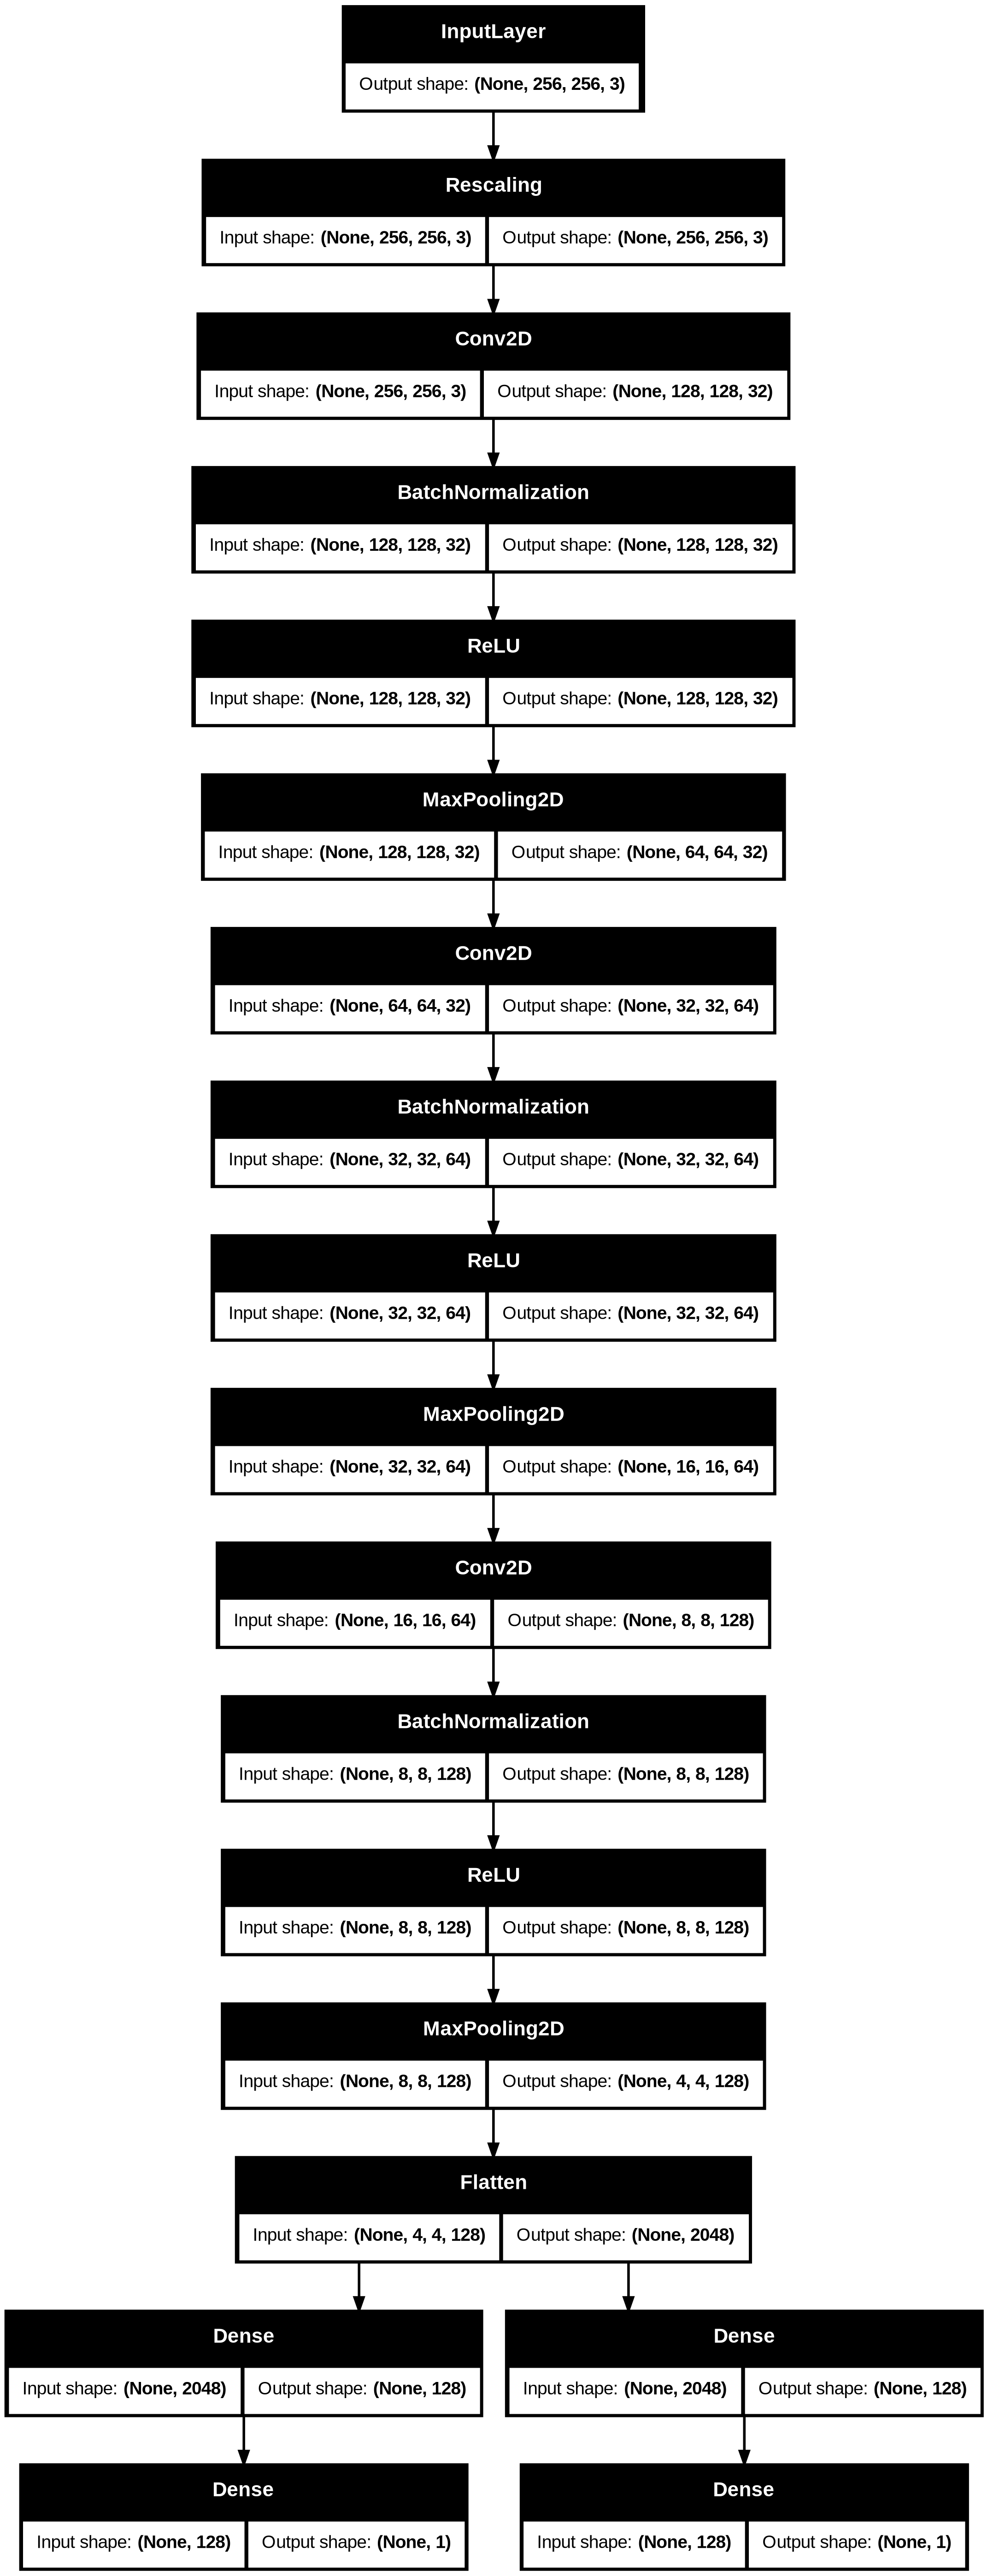

In [ ]:
model.compile(
    optimizer="adam",
    loss={"age_output": "mse", "gender_output": "binary_crossentropy"},
    loss_weights={"age_output": 0.01, "gender_output": 1.0}
)

plot_model(model, show_shapes = True)

# Example 2 : 2 Input 1 output

Inputs :
1. Product Image
2. Product Meta Data (Tabular Data)

Output : Price of the product

In [13]:
# Input Layers
img = Input(shape=(224, 224, 3))
data = Input(shape=(10,))

# Image Part
x = Rescaling(1./255)(img)
x = Conv2D(32, kernel_size=(2,2), strides=2, padding='valid')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D()(x)

x = Conv2D(64, kernel_size=(2,2), strides=2, padding='valid')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D()(x)

x = Conv2D(128, kernel_size=(2,2), strides=2, padding='valid')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D()(x)

# Correctly flatten the image features
x = Flatten()(x)

# Tabular Data Part
y = Dense(128)(data)
y = BatchNormalization()(y)
y = ReLU()(y)
y = Dropout(0.2)(y)

y = Dense(64)(y)
y = BatchNormalization()(y)
y = ReLU()(y)
y = Dropout(0.2)(y)

y = Dense(32)(y)
y = BatchNormalization()(y)
y = ReLU()(y)
y = Dropout(0.2)(y)

# Concatenation (both are now 2D tensors)
combined = concatenate([x, y])

# Combined NN
z = Dense(128, activation='relu')(combined)
price_output = Dense(1, activation='linear')(z)

model2 = Model(inputs=[img, data], outputs=price_output)
model2.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_4         │ (None, 224, 224,  │          0 │ input_layer_5[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 112, 112,  │        416 │ rescaling_4[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_6       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 128)       │      1,408 │ input_layer_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_12 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_12[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 56, 56,    │          0 │ re_lu_12[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_15 (ReLU)     │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 28, 28,    │      8,256 │ max_pooling2d_12… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ re_lu_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_13[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_13 (ReLU)     │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_13[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_13    │ (None, 14, 14,    │          0 │ re_lu_13[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_16 (ReLU)     │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 206,913 (808.25 KB)

 Trainable params: 206,017 (804.75 KB)

 Non-trainable params: 896 (3.50 KB)

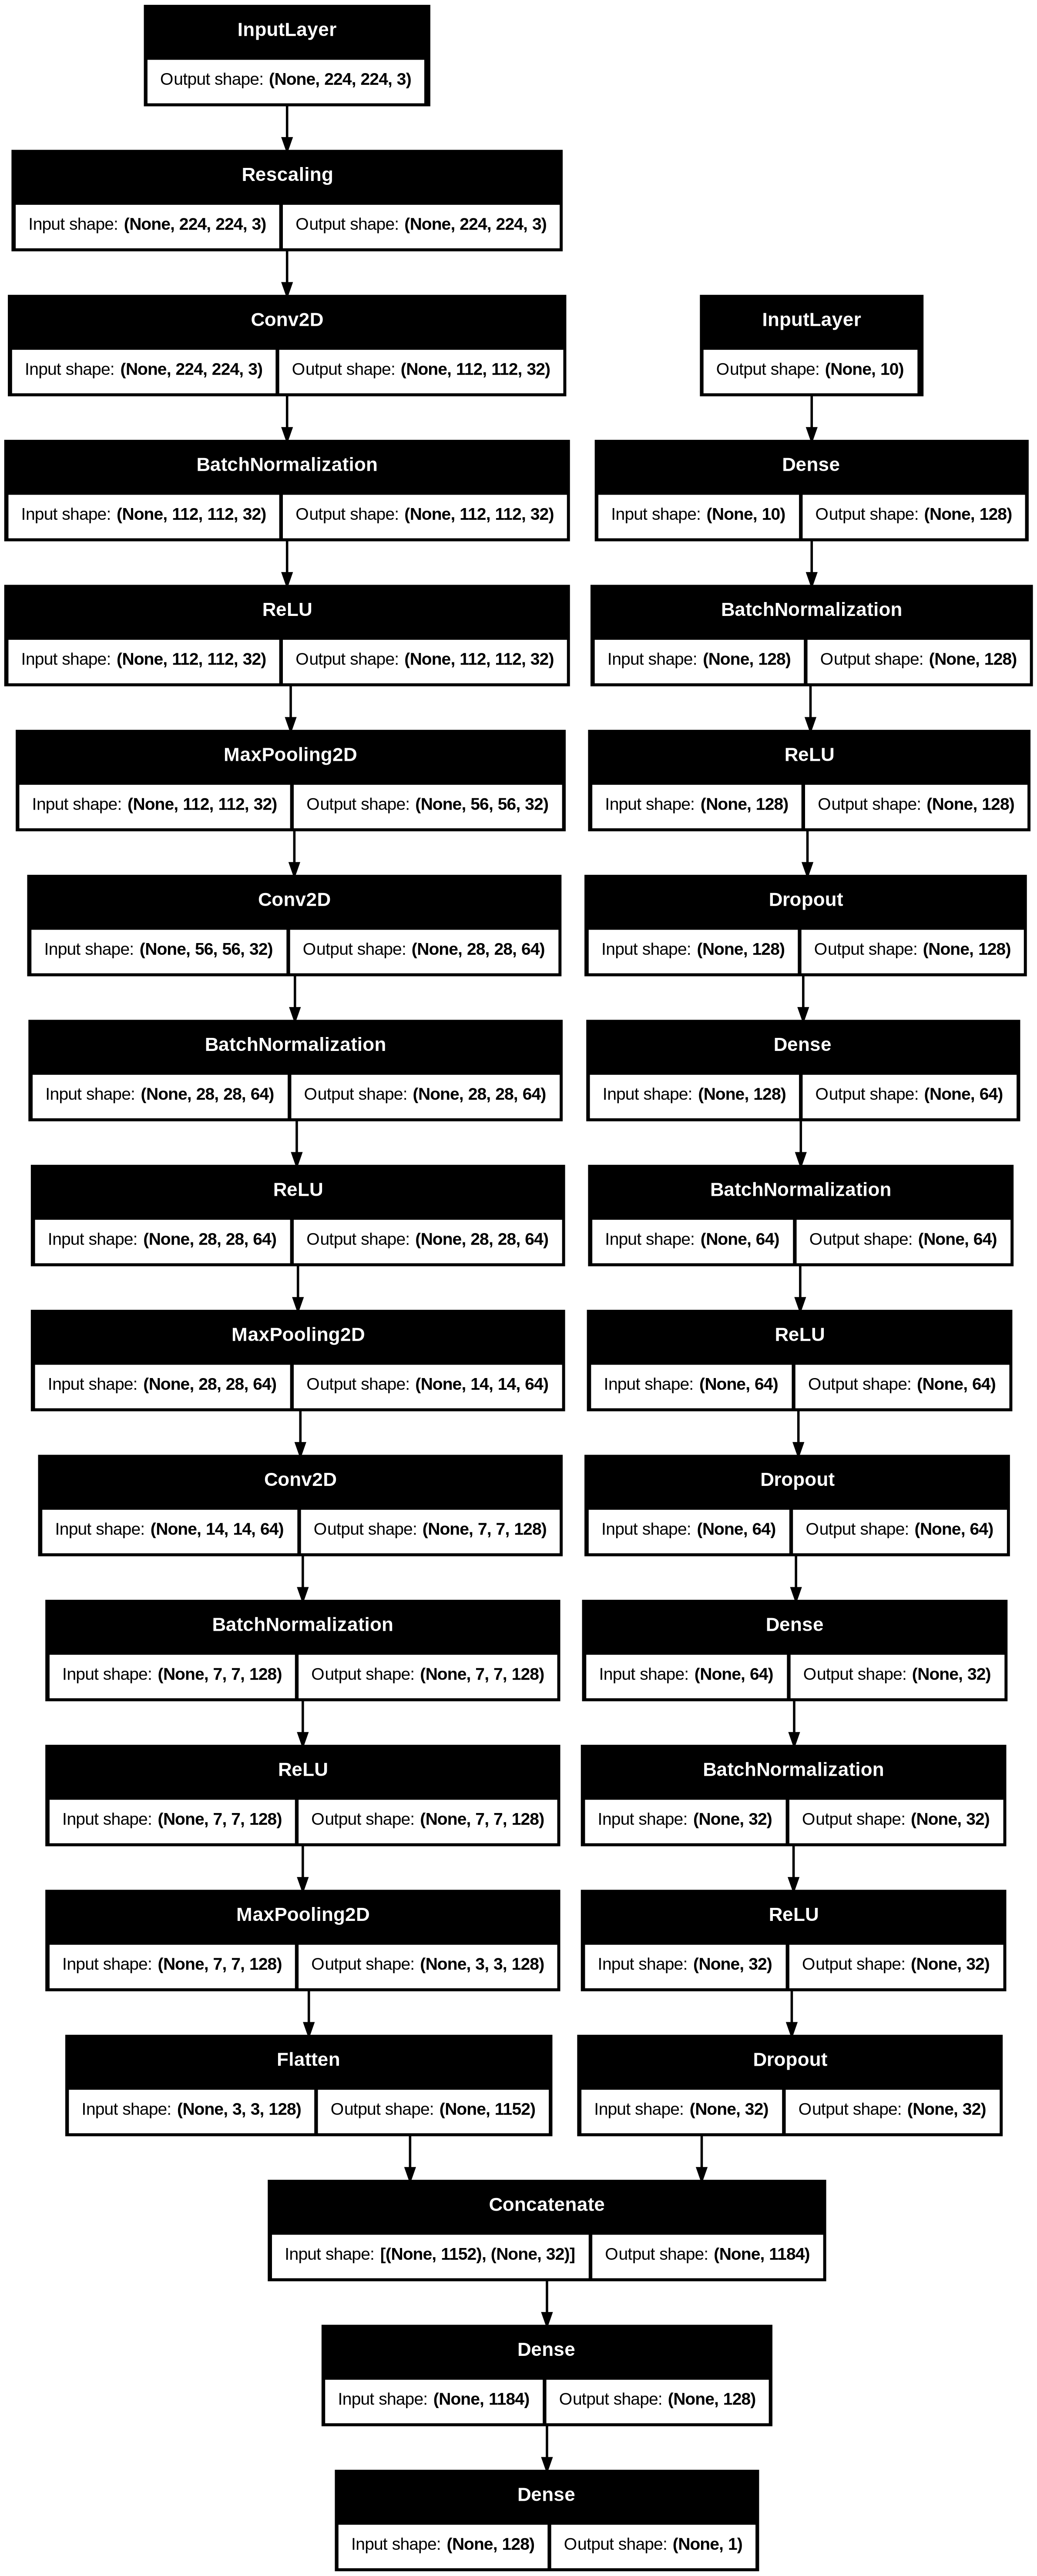

In [17]:
plot_model(model2, show_shapes=True)

# Example 3 : Multi-Input and Multi-Output Model

**Inputs**:
1. **Product Image** (Visual data processed via VGG16's pre-trained convolutional layers)
2. **Product Metadata** (10-dimensional tabular numeric data)

**Outputs**:
1. **Product Category** (Multi-class Classification - predicting 1 of 15 categories)
2. **Price** (Regression - predicting continuous value)


In [15]:
# 1. Inputs
img_input = Input(shape=(224, 224, 3), name='image_input')
meta_input = Input(shape=(10,), name='metadata_input')

# 2. Image Feature Extraction using VGG16 Conv Base
# Preprocess inputs for VGG16 compatibility
x_img = preprocess_input(img_input)

# Load pre-trained VGG16 without the classifier top layers
vgg_base = VGG16(include_top=False, weights='imagenet', input_tensor=x_img)

# Freeze VGG16 convolutional layers to retain pre-trained features
for layer in vgg_base.layers:
    layer.trainable = False

# Flatten the extracted image feature maps
x_img_features = Flatten()(vgg_base.output)

# 3. Tabular Feature Extraction
x_meta = Dense(64)(meta_input)
x_meta = BatchNormalization()(x_meta)
x_meta = ReLU()(x_meta)
x_meta = Dropout(0.2)(x_meta)

# 4. Merging the Image & Tabular features
combined_features = concatenate([x_img_features, x_meta])

# Combined Representation Layer
x_shared = Dense(256, activation='relu')(combined_features)

# 5. Multi-Outputs
category_output = Dense(15, activation='softmax', name='category_output')(x_shared)
price_output = Dense(1, activation='linear', name='price_output')(x_shared)

# 6. Instantiate and Summarize Model
model3 = Model(inputs=[img_input, meta_input], outputs=[category_output, price_output])
model3.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ image_input[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ image_input[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 224, 224,  │      1,792 │ add[0][0]         │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 224, 224,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 112, 112,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 112, 112,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 56, 56,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 56, 56,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 56, 56,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 56, 56,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 28, 28,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 28, 28,    │  1,180,160 │ block3_pool[0][0

 Total params: 21,158,928 (80.71 MB)

 Trainable params: 6,444,112 (24.58 MB)

 Non-trainable params: 14,714,816 (56.13 MB)

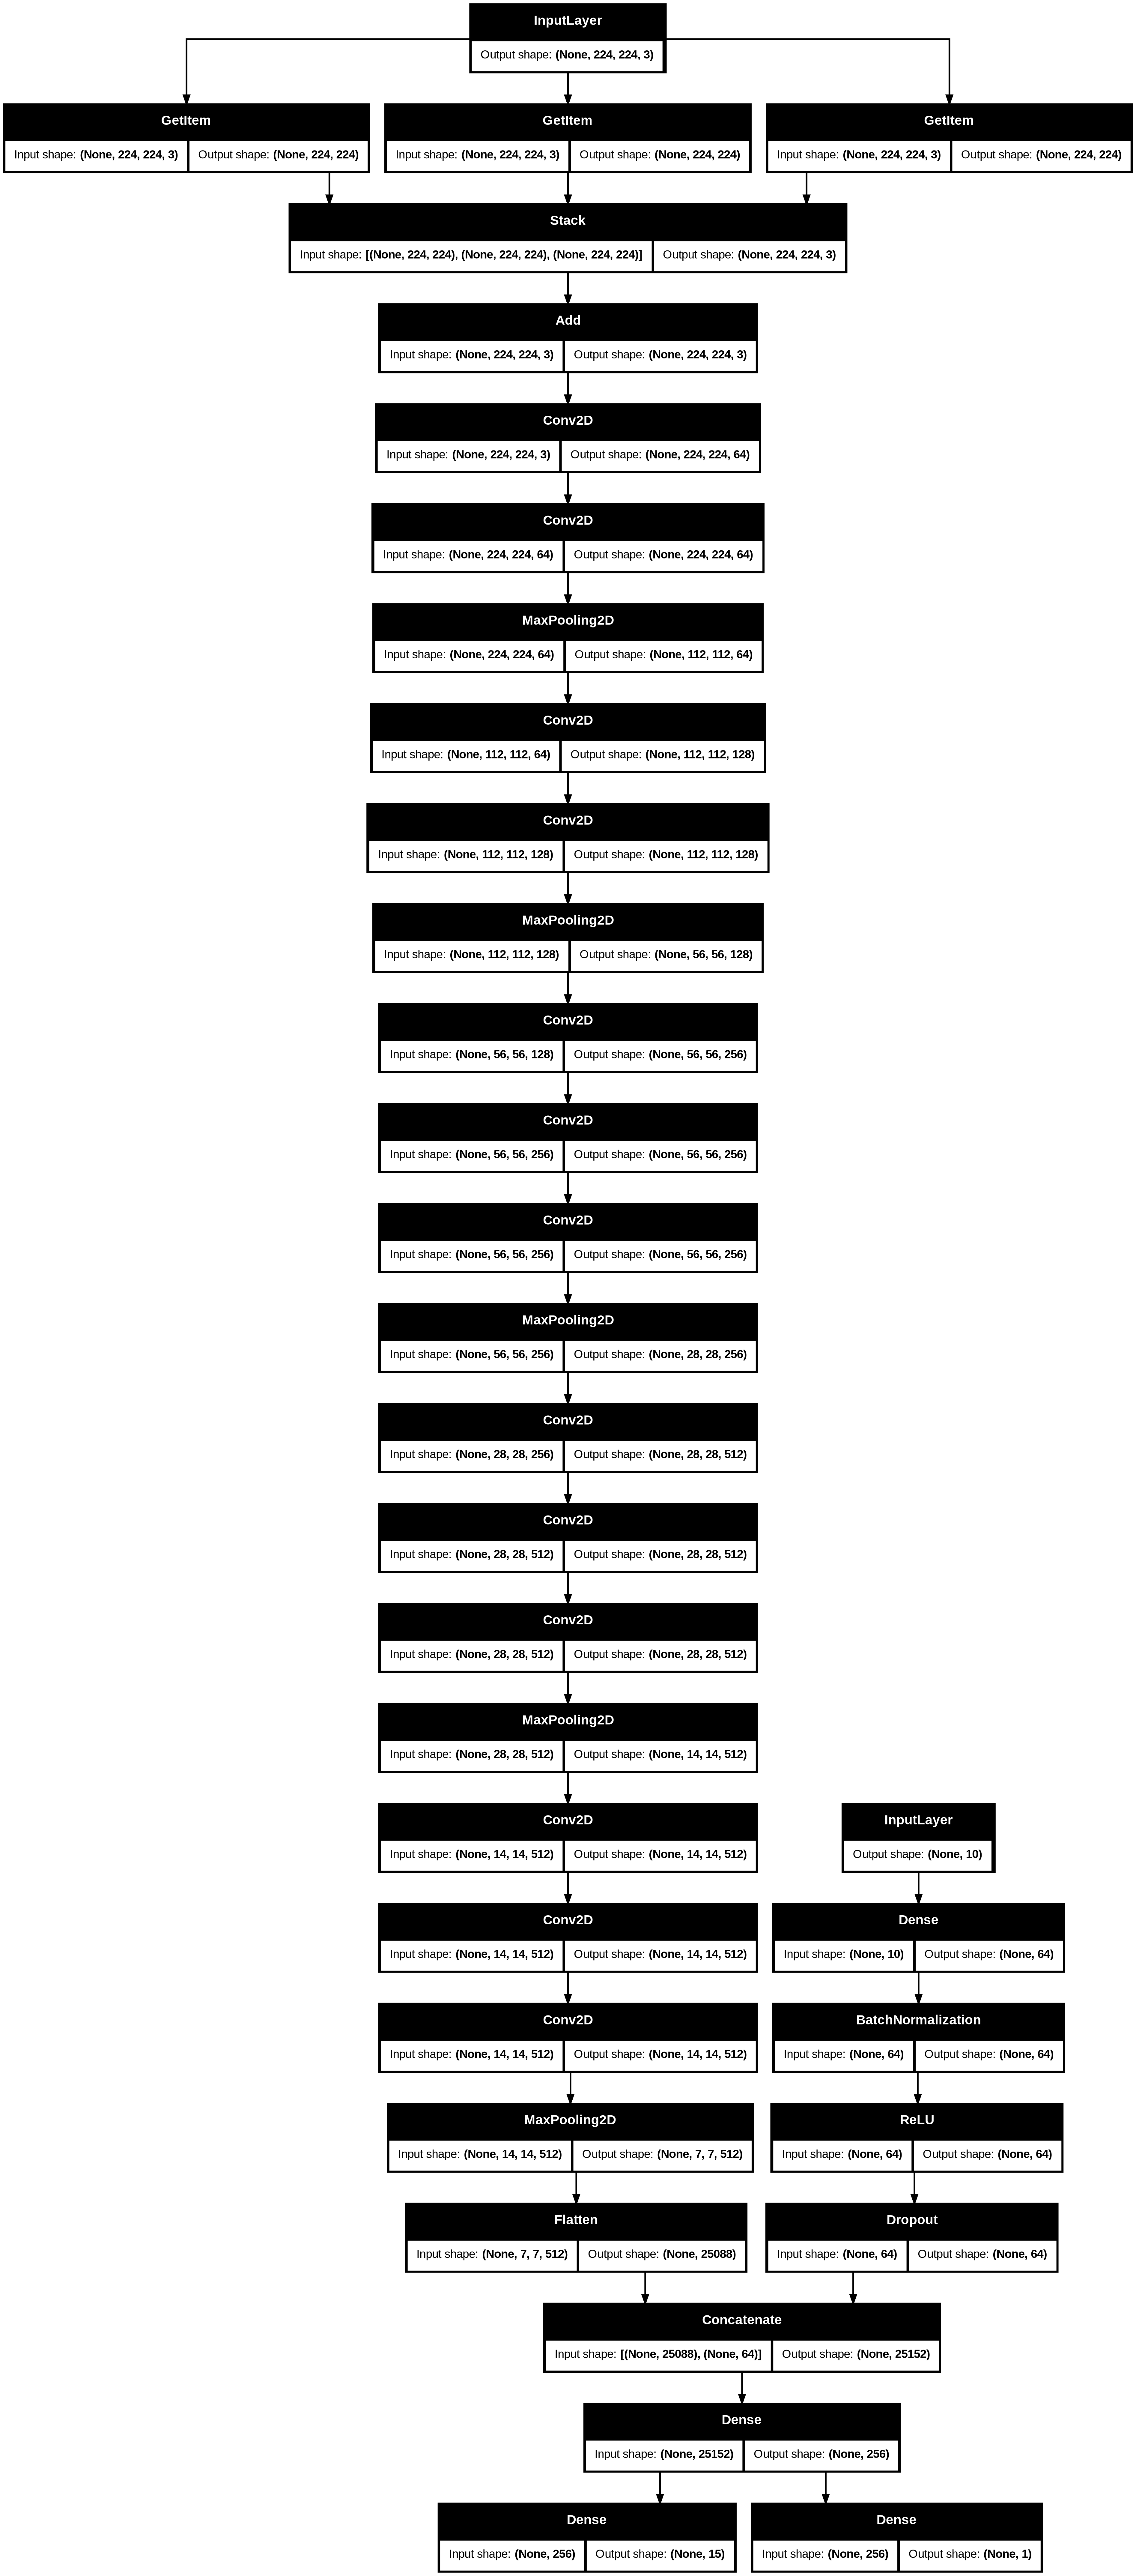

In [ ]:
model.compile(
    optimizer="adam",
    loss={"category_output": "categorial_crossentropy", "price_output": "mae"},
    loss_weights={"price_output": 0.01, "category_output": 1.0}
)

plot_model(model3, show_shapes=True)